## Dataset structure verification

In [1]:
from pathlib import Path

PARENT_DIR = Path.cwd().parent

RAW_DIR = PARENT_DIR/"data/celeba/raw"

IMAGE_DIR = RAW_DIR / "img_align_celeba"

print("Dataset directory:", RAW_DIR.resolve())
print("Image directory exists:", IMAGE_DIR.exists())

print("\nAvailable annotation files:")

for file in RAW_DIR.iterdir():
    if file.is_file():
        print(f"{file.name} — {file.stat().st_size / (1024**2):.2f} MB")

Dataset directory: Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)\data\celeba\raw
Image directory exists: True

Available annotation files:
identity_CelebA.txt — 3.27 MB
img_align_celeba.zip — 1376.62 MB
list_attr_celeba.txt — 25.48 MB
list_eval_partition.txt — 2.70 MB
list_landmarks_align_celeba.txt — 11.59 MB


In [2]:
# Count extracted images

image_files = list(IMAGE_DIR.glob('*.jpg'))

print('Total Extracted Images: ',len(image_files))

print("\nSample filenames:")

for image in image_files[:5]:
    print(image.name)

Total Extracted Images:  202599

Sample filenames:
000001.jpg
000002.jpg
000003.jpg
000004.jpg
000005.jpg


In [3]:
# Annotation Files 

annotation_files = {
    "Identity": RAW_DIR / "identity_CelebA.txt",
    "Attributes": RAW_DIR / "list_attr_celeba.txt",
    "Partitions": RAW_DIR / "list_eval_partition.txt",
    "Landmarks": RAW_DIR / "list_landmarks_align_celeba.txt"
}

# inspect the aannotation_files

for name,path in annotation_files.items():
    print()
    print(f'{name.upper()}:')
    print()

    with open(path,'r') as f:
        for _ in range(3):
            line = f.readline()
            if not line:
                break
            print(line.rstrip())



IDENTITY:

000001.jpg 2880
000002.jpg 2937
000003.jpg 8692

ATTRIBUTES:

202599
5_o_Clock_Shadow Arched_Eyebrows Attractive Bags_Under_Eyes Bald Bangs Big_Lips Big_Nose Black_Hair Blond_Hair Blurry Brown_Hair Bushy_Eyebrows Chubby Double_Chin Eyeglasses Goatee Gray_Hair Heavy_Makeup High_Cheekbones Male Mouth_Slightly_Open Mustache Narrow_Eyes No_Beard Oval_Face Pale_Skin Pointy_Nose Receding_Hairline Rosy_Cheeks Sideburns Smiling Straight_Hair Wavy_Hair Wearing_Earrings Wearing_Hat Wearing_Lipstick Wearing_Necklace Wearing_Necktie Young
000001.jpg -1  1  1 -1 -1 -1 -1 -1 -1 -1 -1  1 -1 -1 -1 -1 -1 -1  1  1 -1  1 -1 -1  1 -1 -1  1 -1 -1 -1  1  1 -1  1 -1  1 -1 -1  1

PARTITIONS:

000001.jpg 0
000002.jpg 0
000003.jpg 0

LANDMARKS:

202599
lefteye_x lefteye_y righteye_x righteye_y nose_x nose_y leftmouth_x leftmouth_y rightmouth_x rightmouth_y
000001.jpg 69  109  106  113   77  142   73  152  108  154


## Annotation interpretation

### 1. Identity annotations

```
000001.jpg 2880
000002.jpg 2937
000003.jpg 8692
```

| Column       | Meaning        |
| ------------ | -------------- |
| `000001.jpg` | Image filename |
| `2880`       | Identity ID    |

Important: Identity IDs are categorical labels, not numerical measurements.

For example, images with identity `2880` belong to the same person.

### 2. Facial attributes

You have 40 facial attributes.

Example:

```
000001.jpg -1 1 1 -1 -1 ...
```

- `1` = Attribute present.
- `-1` = Attribute absent.

For example, `Male`, `Smiling`, `Eyeglasses`, etc.

These attributes describe the face, not the person's identity.

### 3. Dataset partitions

```
000001.jpg 0
000002.jpg 0
000003.jpg 0
```

The standard CelebA partition mapping is:

| Label | Partition  |
| ----- | ---------- |
| 0     | Training   |
| 1     | Validation |
| 2     | Testing    |

### 4. Facial landmarks

Your dataset contains five facial landmark positions:

- Left eye
- Right eye
- Nose
- Left mouth corner
- Right mouth corner

Each landmark has an X and Y coordinate.

These coordinates will be useful when we implement face alignment.

## Identity distribution and annotation consistency

In [4]:
# Load annotation files

import pandas as pd 
from collections import Counter

identity_df = pd.read_csv(
    RAW_DIR / "identity_CelebA.txt",
    sep=r"\s+",
    names=["filename", "identity"]
)

partition_df = pd.read_csv(
    RAW_DIR / "list_eval_partition.txt",
    sep=r"\s+",
    names=["filename", "partition"]
)

print("Identity shape:", identity_df.shape)
print("Partition shape:", partition_df.shape)

Identity shape: (202599, 2)
Partition shape: (202599, 2)


In [5]:
# Analyze identity distribution

identity_counts = identity_df["identity"].value_counts()

print("Total images:", len(identity_df))
print("Unique identities:", identity_df["identity"].nunique())

print("\nImages per identity:")
print(identity_counts.describe())

print("\nTop 10 identities with most images:")
print(identity_counts.head(10))

print("\nIdentities with only one image:",
      (identity_counts == 1).sum())

Total images: 202599
Unique identities: 10177

Images per identity:
count    10177.000000
mean        19.907537
std          8.925916
min          1.000000
25%         13.000000
50%         21.000000
75%         29.000000
max         35.000000
Name: count, dtype: float64

Top 10 identities with most images:
identity
3227    35
3782    35
2820    35
3699    34
3745    34
9152    32
8968    32
9256    32
4887    31
6568    31
Name: count, dtype: int64

Identities with only one image: 44


In [6]:
# Verify annotation consistency

image_names = {p.name for p in IMAGE_DIR.glob("*.jpg")}

annotation_names = set(identity_df["filename"])

print("Images missing from annotations:",
      len(image_names - annotation_names))

print("Annotations without images:",
      len(annotation_names - image_names))

print("Duplicate annotation filenames:",
      identity_df["filename"].duplicated().sum())

print("Duplicate identity-partition filenames:",
      partition_df["filename"].duplicated().sum())

Images missing from annotations: 0
Annotations without images: 0
Duplicate annotation filenames: 0
Duplicate identity-partition filenames: 0


In [7]:
# Partition distribution

partition_counts = partition_df["partition"].value_counts().sort_index()

partition_counts.index = ["Train", "Validation", "Test"]

print(partition_counts)

print("\nPercentage distribution:")
print((partition_counts / len(partition_df) * 100).round(2))

Train         162770
Validation     19867
Test           19962
Name: count, dtype: int64

Percentage distribution:
Train         80.34
Validation     9.81
Test           9.85
Name: count, dtype: float64


In [8]:
#  check identity overlap 

# Combine identity and partition annotations

merged_df = identity_df.merge(
    partition_df,
    on="filename",
    how="inner"
)

# Number of unique partitions per identity
identity_split_counts = (
    merged_df.groupby("identity")["partition"]
    .nunique()
)

# Identities appearing in multiple partitions
overlapping_identities = identity_split_counts[
    identity_split_counts > 1
]

print("Identities appearing in multiple partitions:",
      len(overlapping_identities))

print("Identities appearing in only one partition:",
      (identity_split_counts == 1).sum())

print("\nIdentity overlap percentage:",
      round(len(overlapping_identities) /
            len(identity_split_counts) * 100, 2), "%")

Identities appearing in multiple partitions: 0
Identities appearing in only one partition: 10177

Identity overlap percentage: 0.0 %


# Identity-based dataset filtering

In [9]:
MIN_IMAGES = 20

# Select identities with at least 20 images
eligible_identities = identity_counts[
    identity_counts >= MIN_IMAGES
].index

# Filter identity annotations
filtered_identity_df = identity_df[
    identity_df['identity'].isin(eligible_identities)
].copy()

# Preserve official partition information
filtered_df = filtered_identity_df.merge(
    partition_df,
    on="filename",
    how="inner"
)

print("Original images:", len(identity_df))
print("Filtered images:", len(filtered_df))

print("\nOriginal identities:", identity_df["identity"].nunique())
print("Filtered identities:", filtered_df["identity"].nunique())

print("\nExcluded identities:",
      identity_df["identity"].nunique() - filtered_df["identity"].nunique())

Original images: 202599
Filtered images: 163749

Original identities: 10177
Filtered identities: 6348

Excluded identities: 3829


In [10]:
partition_summary = filtered_df.groupby("partition").agg(
    images=("filename", "count"),
    identities=("identity", "nunique")
)

partition_summary.index = ["Train", "Validation", "Test"]

print(partition_summary)

            images  identities
Train       131442        5103
Validation   16280         629
Test         16027         616


## Create the filtered dataset manifest

In [11]:
PROCESSED_DIR = PARENT_DIR/Path("data/celeba/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

manifest_df = filtered_df[
    ["filename", "identity", "partition"]
].copy()

manifest_df = manifest_df.sort_values(
    ["partition", "identity", "filename"]
).reset_index(drop=True)

MANIFEST_PATH = PROCESSED_DIR / "filtered_manifest.csv"

manifest_df.to_csv(MANIFEST_PATH, index=False)

print("Manifest saved successfully!")
print("Location:", MANIFEST_PATH.resolve())
print("Total records:", len(manifest_df))

Manifest saved successfully!
Location: Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)\data\celeba\processed\filtered_manifest.csv
Total records: 163749


## Understand the filtered dataset visually

In [12]:
from PIL import Image

sample_images = manifest_df['filename'].head(5)

for filename in sample_images:
    image_path = IMAGE_DIR/filename

    with Image.open(image_path) as img:
        print(
            f"{filename} | "
            f"Size: {img.size} | "
            f"Format: {img.format} | "
            f"Mode: {img.mode}"
        )

000023.jpg | Size: (178, 218) | Format: JPEG | Mode: RGB
004506.jpg | Size: (178, 218) | Format: JPEG | Mode: RGB
006439.jpg | Size: (178, 218) | Format: JPEG | Mode: RGB
014042.jpg | Size: (178, 218) | Format: JPEG | Mode: RGB
015216.jpg | Size: (178, 218) | Format: JPEG | Mode: RGB


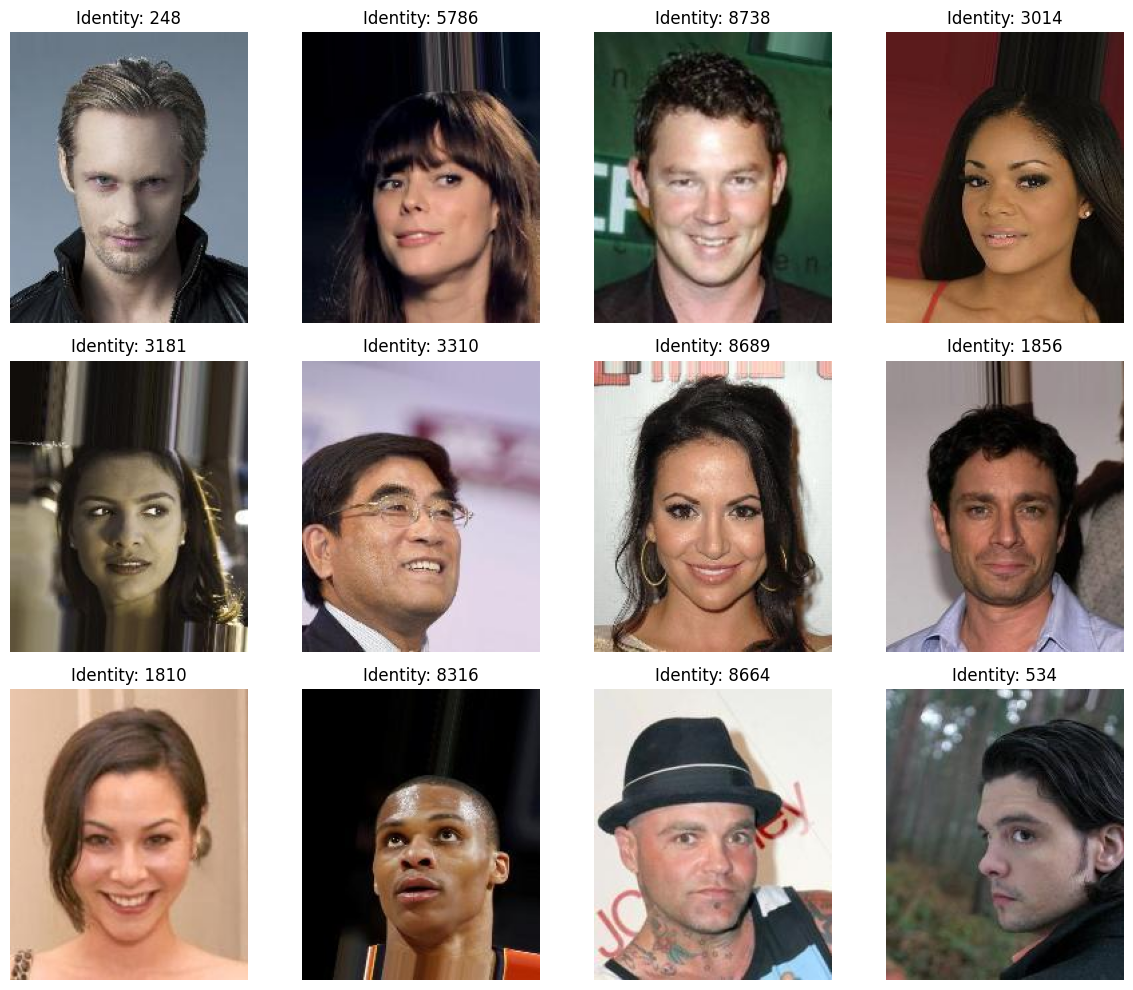

In [13]:
import matplotlib.pyplot as plt
import random

# Select 12 random images
sample_df = manifest_df.sample(
    n=12,
    random_state=42
)

fig, axes = plt.subplots(3, 4, figsize=(12, 10))

for ax,filename,identity in zip(axes.flat, sample_df['filename'].tolist(), sample_df['identity'].tolist()):
    image_path = IMAGE_DIR / filename

    with Image.open(image_path) as img:
        ax.imshow(img)

    ax.set_title(f"Identity: {identity}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Analyze identity distribution after filtering

IDENTITY DISTRIBUTION
-----------------------------------
Identities: 6348
Minimum: 20
Maximum: 35
Mean: 25.8
Median: 27.0

IDENTITIES BY IMAGE COUNT
count
20–24    2687
25–29    1301
30–34    2357
35          3
Name: count, dtype: int64


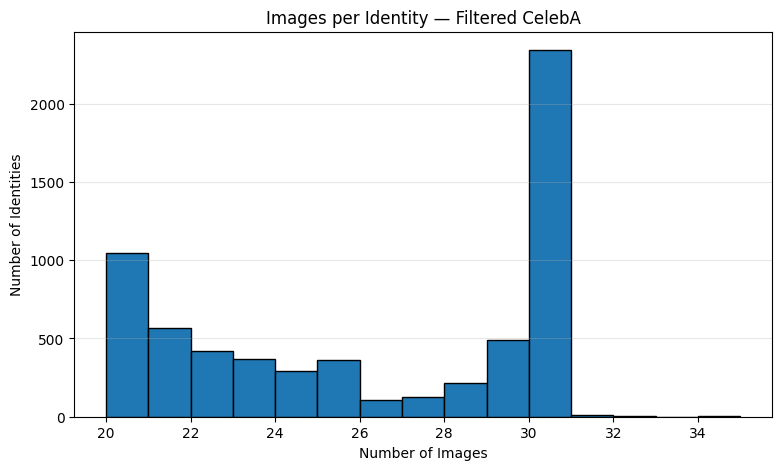

In [14]:
import matplotlib.pyplot as plt

# Images per identity in filtered dataset
filtered_identity_counts = (
    manifest_df["identity"].value_counts()
)

# Statistical summary
print("IDENTITY DISTRIBUTION")
print("-" * 35)

print("Identities:", len(filtered_identity_counts))
print("Minimum:", filtered_identity_counts.min())
print("Maximum:", filtered_identity_counts.max())
print("Mean:", round(filtered_identity_counts.mean(), 2))
print("Median:", filtered_identity_counts.median())

# Image-count ranges
bins = [20, 25, 30, 35, 40]
labels = ["20–24", "25–29", "30–34", "35"]

identity_ranges = pd.cut(
    filtered_identity_counts,
    bins=bins,
    labels=labels,
    right=False
)

print("\nIDENTITIES BY IMAGE COUNT")
print(identity_ranges.value_counts().sort_index())

# Distribution plot
plt.figure(figsize=(9, 5))

plt.hist(
    filtered_identity_counts,
    bins=15,
    edgecolor="black"
)

plt.title("Images per Identity — Filtered CelebA")
plt.xlabel("Number of Images")
plt.ylabel("Number of Identities")
plt.grid(axis="y", alpha=0.3)

plt.show()

## Prepare train, validation and test manifests

In [15]:
# Split filtered manifest by official CelebA partitions

train_df = manifest_df[manifest_df["partition"] == 0].copy()
val_df   = manifest_df[manifest_df["partition"] == 1].copy()
test_df  = manifest_df[manifest_df["partition"] == 2].copy()

# Save individual manifests
train_df.to_csv(PROCESSED_DIR / "train.csv", index=False)
val_df.to_csv(PROCESSED_DIR / "validation.csv", index=False)
test_df.to_csv(PROCESSED_DIR / "test.csv", index=False)

print("Split manifests saved successfully!")

print("\nTrain:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Split manifests saved successfully!

Train: 131442
Validation: 16280
Test: 16027


# Visualize facial landmarks

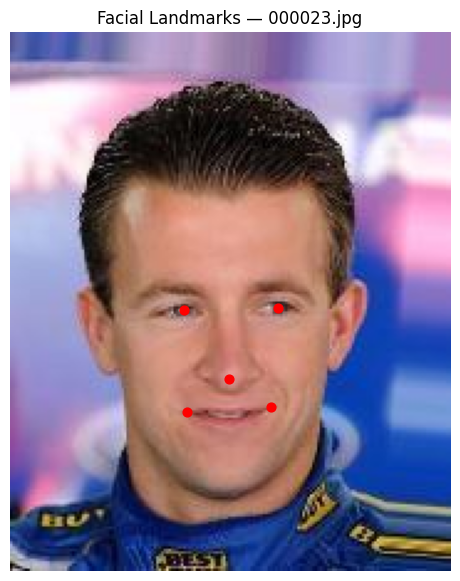

In [16]:
# Load the five-point landmark annotations
landmarks_df = pd.read_csv(
    RAW_DIR / "list_landmarks_align_celeba.txt",
    sep=r"\s+",
    skiprows=1
)

# Select one image
sample_filename = manifest_df.iloc[0]["filename"]

landmark_row = landmarks_df[
    landmarks_df.index == sample_filename
].iloc[0]

# Load image
image = Image.open(IMAGE_DIR / sample_filename)

# Landmark coordinates
landmark_columns = [
    "lefteye_x", "lefteye_y",
    "righteye_x", "righteye_y",
    "nose_x", "nose_y",
    "leftmouth_x", "leftmouth_y",
    "rightmouth_x", "rightmouth_y"
]

coordinates = landmark_row[landmark_columns].values.reshape(5, 2)

# Display landmarks
plt.figure(figsize=(6, 7))
plt.imshow(image)

plt.scatter(
    coordinates[:, 0],
    coordinates[:, 1],
    color="red",
    s=40,
    marker="o"
)

plt.title(f"Facial Landmarks — {sample_filename}")
plt.axis("off")
plt.show()

## Check for corrupted or unreadable images

In [17]:
from PIL import Image
from tqdm.auto import tqdm
from pathlib import Path

corrupted_images = []

for filename in tqdm(
    manifest_df["filename"],
    desc="Checking image integrity",
    unit="image"
):
    image_path = IMAGE_DIR / filename

    try:
        with Image.open(image_path) as img:
            img.verify()

    except Exception as error:
        corrupted_images.append({
            "filename": filename,
            "error": str(error)
        })

print(f"Total images checked: {len(manifest_df):,}")
print(f"Corrupted/unreadable images: {len(corrupted_images):,}")

if corrupted_images:
    corrupted_df = pd.DataFrame(corrupted_images)

    corrupted_df.to_csv(
        PROCESSED_DIR / "corrupted_images.csv",
        index=False
    )

    display(corrupted_df.head())
else:
    print("All filtered images passed the integrity check!")

Checking image integrity:   0%|          | 0/163749 [00:00<?, ?image/s]

Total images checked: 163,749
Corrupted/unreadable images: 0
All filtered images passed the integrity check!


## image preprocessing

In [18]:
from torchvision import transforms

train_transform = transforms.Compose([

    transforms.Resize((112,112)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(degrees=5),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5,0.5,0.5],
        std=[0.5,0.5,0.5]
    )
    
])

eval_transform = transforms.Compose([

    transforms.Resize((112,112)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5,0.5,0.5],
        std=[0.5,0.5,0.5]
    )
])

In [19]:
from torch.utils.data import Dataset

class FaceRecognitionDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):

        self.dataframe = dataframe.reset_index(drop = True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self,index):

        row = self.dataframe.iloc[index]

        image_path = self.image_dir / row["filename"]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        identity = int(row["identity"])

        return image,identity

In [20]:
# creating the training dataset 

train_df = manifest_df[
    manifest_df['partition'] == 0
].copy()

train_dataset = FaceRecognitionDataset(
    dataframe=train_df,
    image_dir=IMAGE_DIR,
    transform=train_transform
)

print("Total training images:", len(train_dataset))

Total training images: 131442


In [21]:
sample_image, sample_identity = train_dataset[0]

print("Image tensor shape:", sample_image.shape)
print("Identity label:", sample_identity)
print("Tensor data type:", sample_image.dtype)

Image tensor shape: torch.Size([3, 112, 112])
Identity label: 1
Tensor data type: torch.float32


In [22]:
# Create validation and test datasets

val_df = manifest_df[
    manifest_df["partition"] == 1
].copy()

test_df = manifest_df[
    manifest_df["partition"] == 2
].copy()

val_dataset = FaceRecognitionDataset(
    dataframe=val_df,
    image_dir=IMAGE_DIR,
    transform=eval_transform
)

test_dataset = FaceRecognitionDataset(
    dataframe=test_df,
    image_dir=IMAGE_DIR,
    transform=eval_transform
)

print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Validation dataset: 16280
Test dataset: 16027


In [23]:
val_image, val_identity = val_dataset[0]
test_image, test_identity = test_dataset[0]

print("\nValidation sample:")
print("Shape:", val_image.shape)
print("Identity:", val_identity)

print("\nTest sample:")
print("Shape:", test_image.shape)
print("Identity:", test_identity)


Validation sample:
Shape: torch.Size([3, 112, 112])
Identity: 18

Test sample:
Shape: torch.Size([3, 112, 112])
Identity: 4930


## Configure DataLoaders

In [24]:
import torch
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

In [25]:
images, identities = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch identity shape:", identities.shape)
print("Batch image dtype:", images.dtype)
print("Unique identities in batch:", identities.unique().numel())

Batch image shape: torch.Size([32, 3, 112, 112])
Batch identity shape: torch.Size([32])
Batch image dtype: torch.float32
Unique identities in batch: 32


In [26]:
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 4108
Validation batches: 509
Test batches: 501


## transforms.py

In [27]:
%%writefile "$PARENT_DIR/src/transforms.py"

from torchvision import transforms


def get_train_transforms():

    return transforms.Compose([
        transforms.Resize((112, 112)),

        transforms.RandomHorizontalFlip(p=0.5),

        transforms.RandomRotation(degrees=5),

        transforms.ColorJitter(
            brightness=0.15,
            contrast=0.15
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=[0.5, 0.5, 0.5],
            std=[0.5, 0.5, 0.5]
        )
    ])


def get_eval_transforms():

    return transforms.Compose([
        transforms.Resize((112, 112)),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=[0.5, 0.5, 0.5],
            std=[0.5, 0.5, 0.5]
        )
    ])

Overwriting Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)/src/transforms.py


In [28]:
from pathlib import Path
import sys

# Get the project root (parent of notebooks/)
PROJECT_ROOT = Path.cwd().parent

# Add project root to Python's import search path
sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("Transforms file exists:", (PROJECT_ROOT / "src" / "transforms.py").exists())

Project root: Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)
Transforms file exists: True


In [29]:
from src.transforms import (
    get_train_transforms,
    get_eval_transforms
)

train_transform = get_train_transforms()
eval_transform = get_eval_transforms()

print("Training transforms:", train_transform)
print("Evaluation transforms:", eval_transform)

Training transforms: Compose(
    Resize(size=(112, 112), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-5.0, 5.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.85, 1.15), contrast=(0.85, 1.15), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
)
Evaluation transforms: Compose(
    Resize(size=(112, 112), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
)


## Verify Image Preprocessing

Original image size: (178, 218)


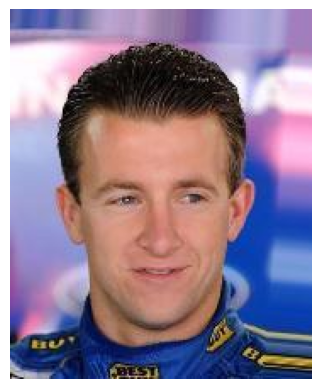

In [30]:
from PIL import Image
import matplotlib.pyplot as plt

image_path = IMAGE_DIR / train_df.iloc[0]["filename"]

image = Image.open(image_path).convert("RGB")

print("Original image size:", image.size)

plt.imshow(image)
plt.axis("off")
plt.show()

In [31]:
train_image = train_transform(image)
eval_image = eval_transform(image)

print("Training tensor:", train_image.shape)
print("Evaluation tensor:", eval_image.shape)
print("Tensor dtype:", eval_image.dtype)
print("Value range:", eval_image.min().item(), eval_image.max().item())

Training tensor: torch.Size([3, 112, 112])
Evaluation tensor: torch.Size([3, 112, 112])
Tensor dtype: torch.float32
Value range: -1.0 1.0


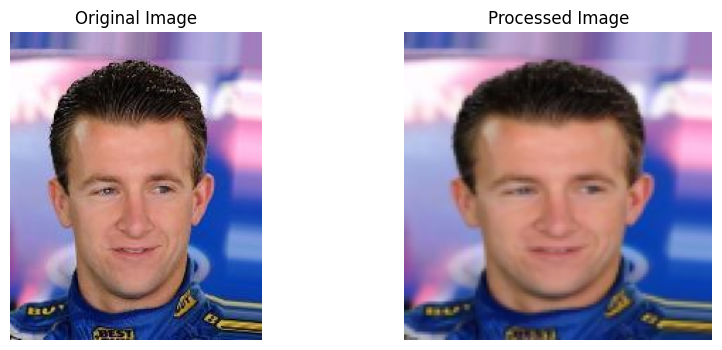

In [32]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(eval_image.permute(1, 2, 0) * 0.5 + 0.5)
plt.title("Processed Image")
plt.axis("off")

plt.show()

## Create src/dataset.py

In [33]:
%%writefile "$PARENT_DIR/src/dataset.py"

from torch.utils.data import Dataset
from PIL import Image

class FaceRecognitionDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = self.image_dir / row["filename"]
        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        identity = int(row["identity"])

        return image, identity

Overwriting Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)/src/dataset.py


In [34]:
from src.dataset import FaceRecognitionDataset

train_dataset = FaceRecognitionDataset(
    dataframe=train_df,
    image_dir=IMAGE_DIR,
    transform=train_transform
)

print("Training dataset size:", len(train_dataset))

Training dataset size: 131442


In [35]:
image, identity = train_dataset[0]

print("Image shape:", image.shape)
print("Identity:", identity)
print("Image dtype:", image.dtype)

Image shape: torch.Size([3, 112, 112])
Identity: 1
Image dtype: torch.float32


In [36]:
val_dataset = FaceRecognitionDataset(
    dataframe=val_df,
    image_dir=IMAGE_DIR,
    transform=eval_transform
)

test_dataset = FaceRecognitionDataset(
    dataframe=test_df,
    image_dir=IMAGE_DIR,
    transform=eval_transform
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Training dataset: 131442
Validation dataset: 16280
Test dataset: 16027


## Create src/dataloader.py

In [37]:
%%writefile "$PARENT_DIR/src/dataloader.py"

from torch.utils.data import DataLoader
import torch 

def create_dataloaders(train_dataset, val_dataset, test_dataset, batch_size=32):

    pin_memory = torch.cuda.is_available()
    
    train_loader = DataLoader(
        train_dataset, 
        batch_size=batch_size,
        shuffle=True, 
        num_workers=0,
        pin_memory=pin_memory
    )

    val_loader = DataLoader(
        val_dataset, 
        batch_size=batch_size,
        shuffle=False, 
        num_workers=0,
        pin_memory=pin_memory
    )

    test_loader = DataLoader(
        test_dataset, 
        batch_size=batch_size,
        shuffle=False, 
        num_workers=0,
        pin_memory=pin_memory
    )

    return train_loader, val_loader, test_loader

Overwriting Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)/src/dataloader.py


In [38]:
from src.dataloader import create_dataloaders

train_loader, val_loader, test_loader = create_dataloaders(
    train_dataset,
    val_dataset,
    test_dataset,
    batch_size=32
)

In [41]:
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 4108
Validation batches: 509
Test batches: 501


In [42]:
images, identities = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch identity shape:", identities.shape)
print("Image dtype:", images.dtype)
print("Identity dtype:", identities.dtype)
print("Pinned memory:", images.is_pinned())

Batch image shape: torch.Size([32, 3, 112, 112])
Batch identity shape: torch.Size([32])
Image dtype: torch.float32
Identity dtype: torch.int64
Pinned memory: True
